In [ ]:

# ============================================================
# RADON x EJI: COUNTY-LEVEL CORRELATION ANALYSIS
# ============================================================

!pip -q install pandas numpy scipy statsmodels seaborn matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, zscore
from statsmodels.stats.multitest import multipletests
from google.colab import files
from pathlib import Path

In [2]:

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------
import pandas as pd
from pathlib import Path

# File paths
eji_path = "/content/EJI_2024_United_States.csv"
radon_path = "/content/radon_us_by_county.csv"
dict_path = "/content/EJI_DATADICTIONARY_2024.csv"

# Load datasets
eji = pd.read_csv(
    eji_path,
    low_memory=False,
    dtype={"STATEFP": str, "COUNTYFP": str}
)

radon = pd.read_csv(
    radon_path,
    low_memory=False
)

# Clean column names
eji.columns = eji.columns.str.strip()
radon.columns = radon.columns.str.strip()

# Load data dictionary if available
descriptions = {}

if Path(dict_path).exists():
    dictionary = pd.read_csv(
        dict_path,
        encoding="utf-8-sig",
        skiprows=1
    )

    dictionary.columns = dictionary.columns.str.strip()

    if {"2024 VARIABLE NAME",
        "2024 VARIABLE DESCRIPTION"}.issubset(dictionary.columns):

        dictionary["2024 VARIABLE NAME"] = (
            dictionary["2024 VARIABLE NAME"]
            .astype(str).str.strip()
        )

        descriptions = dict(zip(
            dictionary["2024 VARIABLE NAME"],
            dictionary["2024 VARIABLE DESCRIPTION"]
        ))

    print("Data dictionary loaded.")
else:
    print("Dictionary not found. Continuing without descriptions.")

# Confirm successful loading
print("\nDATA LOADED SUCCESSFULLY")
print("EJI rows:", len(eji))
print("Radon rows:", len(radon))
print("EJI columns:", len(eji.columns))
print("Radon columns:", len(radon.columns))
print("Dictionary descriptions:", len(descriptions))


Dictionary not found. Continuing without descriptions.

DATA LOADED SUCCESSFULLY
EJI rows: 85188
Radon rows: 2999
EJI columns: 170
Radon columns: 7
Dictionary descriptions: 0


Count variables to sum: []
Variables to average: 134


/tmp/ipykernel_1848/2593594929.py:91: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  eji["weight"] = eji["E_TOTPOP"].where(


Duplicate radon rows: 2

Merge results:
_merge
both          2960
left_only       38
right_only       0
Name: count, dtype: int64
Matched counties with radon: 2960

RADON x EJI CORRELATION SUMMARY
Counties analyzed: 2960
Variables tested: 134
Positive, FDR significant: 36
Negative, FDR significant: 64
Not FDR significant: 34

POSITIVE SIGNIFICANT CORRELATIONS
    variable description        r      p_value        p_fdr  n_counties
     E_SMOKE             0.262782 6.082639e-48 2.093375e-46        2960
   EPL_SMOKE             0.260600 3.757089e-47 8.390832e-46        2960
RPL_CBM_DOM2             0.256039 1.600813e-45 3.064414e-44        2960
  EPL_HOUAGE             0.255126 3.361735e-45 5.630907e-44        2960
    E_HOUAGE             0.253812 9.730586e-45 1.303899e-43        2960
SPL_CBM_DOM2             0.246524 3.156207e-42 3.253321e-41        2960
      E_NEHD             0.203485 4.920833e-29 2.747465e-28        2960
RPL_CBM_DOM1             0.195185 8.384021e-27 4.012353e-26   

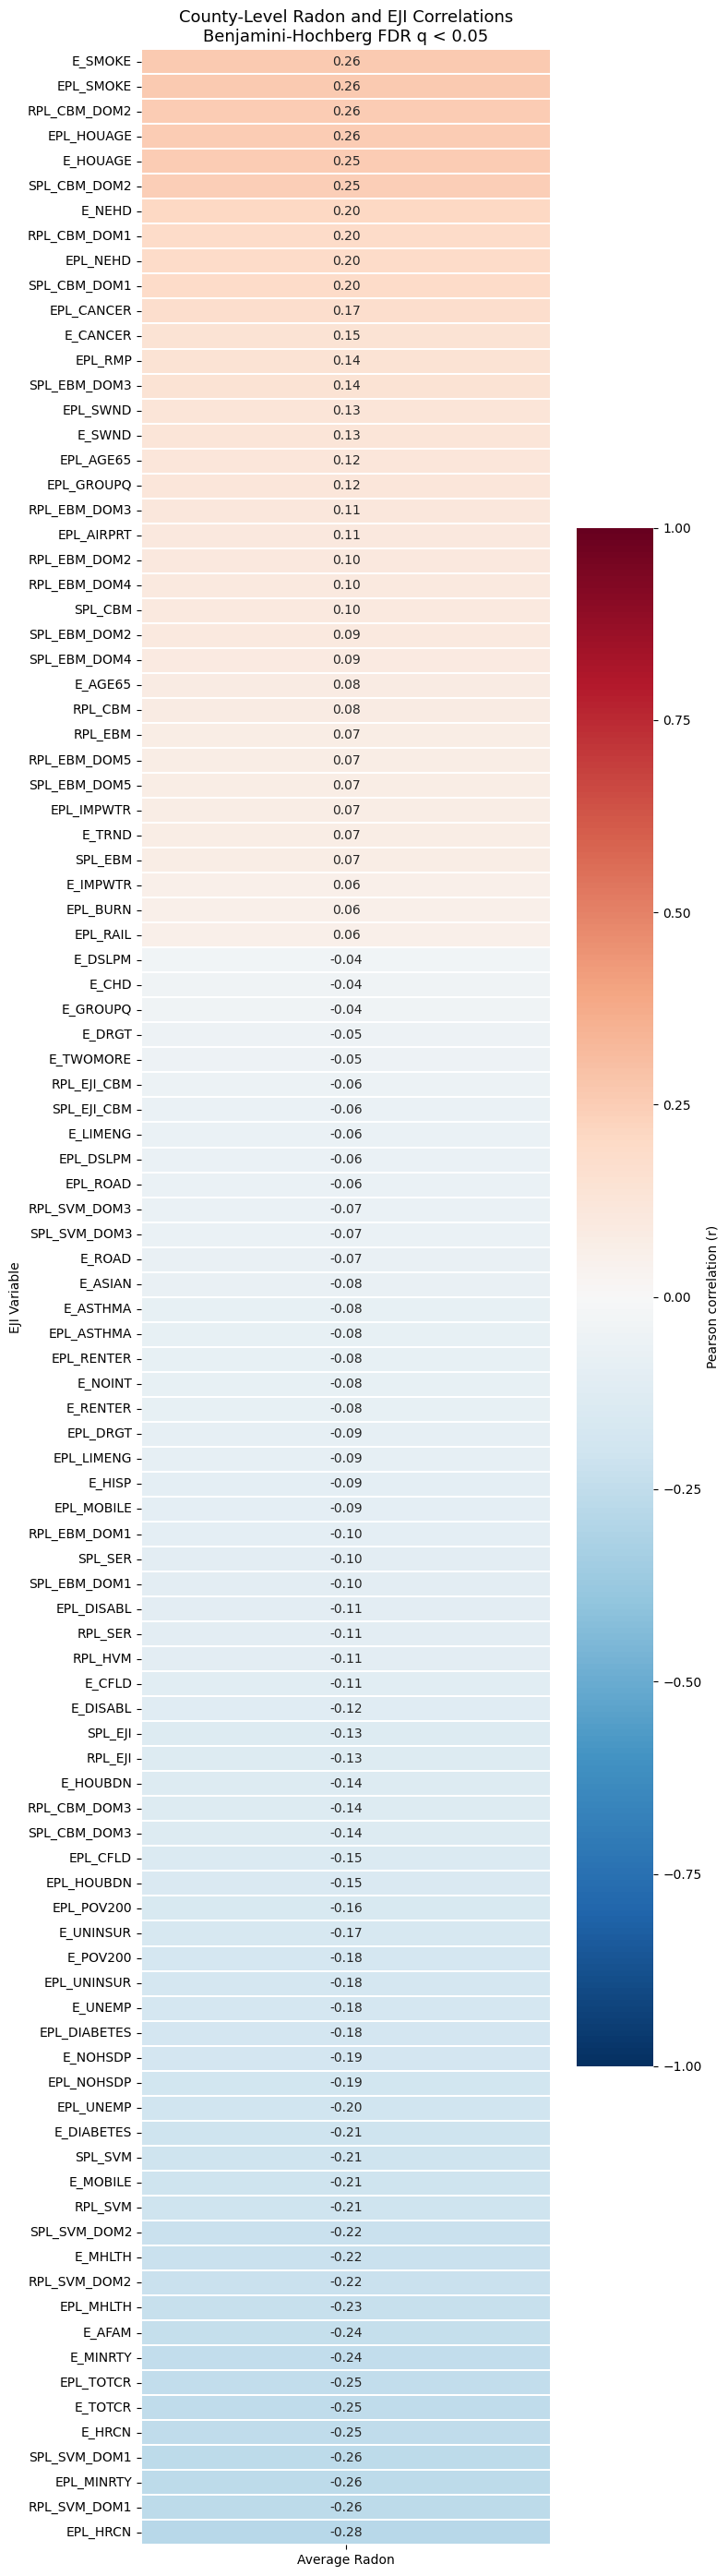

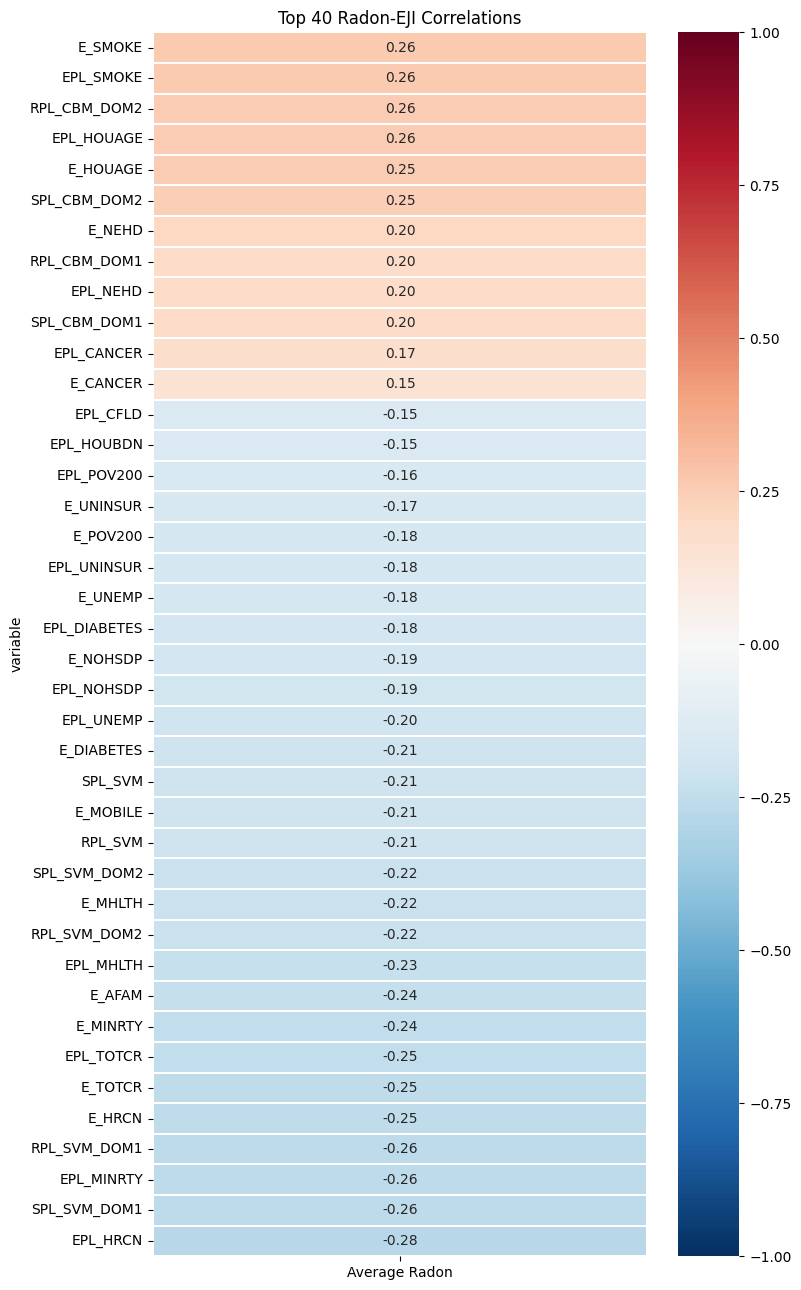


Files saved successfully.


In [3]:


# ------------------------------------------------------------
# 2. CLEAN COUNTY IDENTIFIERS
# ------------------------------------------------------------
# State and county names are normalized for the join.
# State abbreviation prevents cross-state county matches.

eji["STATEABBR"] = eji["STATEABBR"].astype(str).str.upper().str.strip()
radon["state"] = radon["state"].astype(str).str.upper().str.strip()

def clean_county(s):
    return (s.astype(str).str.upper().str.strip()
            .str.replace(r"\s+", " ", regex=True)
            .str.replace(r"\s+(COUNTY|PARISH|BOROUGH)$", "",
                         regex=True)
            .str.replace(r"[^A-Z0-9]", "", regex=True))

eji["county_key"] = clean_county(eji["COUNTY"])
radon["county_key"] = clean_county(radon["county"])

eji["state_key"] = eji["STATEABBR"]
radon["state_key"] = radon["state"]

keys = ["state_key", "county_key"]

# ------------------------------------------------------------
# 3. CLEAN NUMERIC VARIABLES
# ------------------------------------------------------------
# -999 is the EJI missing-data sentinel.
# Other nonnumeric entries become NaN.

exclude = {
    "STATEFP", "COUNTYFP", "TRACTCE", "GEOID",
    "GEOID_2020", "AFFGEOID", "E_TOTPOP",
    "M_TOTPOP", "E_DAYPOP"
}

prefixes = ("E_", "EPL_", "SPL_", "RPL_")

variables = [
    c for c in eji.columns
    if c.startswith(prefixes) and c not in exclude
]

for c in variables:
    eji[c] = pd.to_numeric(eji[c], errors="coerce")
    eji[c] = eji[c].replace(-999, np.nan)

eji["E_TOTPOP"] = pd.to_numeric(
    eji["E_TOTPOP"], errors="coerce"
).replace(-999, np.nan)

radon["avg_radon_pci_l"] = pd.to_numeric(
    radon["avg_radon_pci_l"], errors="coerce"
)

# ------------------------------------------------------------
# 4. AGGREGATE TRACTS TO COUNTIES
# ------------------------------------------------------------
# Population-weighted averages for EJI rates, ranks, scores.
# For E_ variables representing counts, use county totals
# rather than weighted averages.
#
# E_ count indicators are identified by their dictionary
# descriptions. Inspect these classifications before using
# the results in a publication.

count_vars = []
mean_vars = []

for c in variables:
    desc = str(descriptions.get(c, "")).lower()

    is_count = (
        c.startswith("E_")
        and not c.startswith("EPL_")
        and any(term in desc for term in [
            "number of people", "number of persons",
            "number of individuals", "number of households",
            "number of housing units", "population count"
        ])
    )

    if is_count:
        count_vars.append(c)
    else:
        mean_vars.append(c)

print("Count variables to sum:", count_vars)
print("Variables to average:", len(mean_vars))

eji["weight"] = eji["E_TOTPOP"].where(
    eji["E_TOTPOP"] > 0
)

def weighted_mean(group, var):
    x = group[var]
    w = group["weight"]
    valid = x.notna() & w.notna() & (w > 0)
    if valid.sum() == 0:
        return np.nan
    return np.average(x[valid], weights=w[valid])

# County groups
groups = eji.groupby(keys, sort=False, dropna=False)
county_parts = []

for k, g in groups:
    row = {
        "state_key": k[0],
        "county_key": k[1],
        "n_tracts": len(g),
        "county_population": g["E_TOTPOP"].sum(min_count=1)
    }
    for c in mean_vars:
        row[c] = weighted_mean(g, c)
    for c in count_vars:
        row[c] = g[c].sum(min_count=1)
    county_parts.append(row)

county_eji = pd.DataFrame(county_parts)

# One radon record per county; if duplicates exist,
# use their mean (verify duplicate records separately).
duplicate_radon = radon.duplicated(keys, keep=False).sum()
print("Duplicate radon rows:", duplicate_radon)

county_radon = (
    radon.groupby(keys, as_index=False)
    .agg(avg_radon_pci_l=("avg_radon_pci_l", "mean"))
)

# ------------------------------------------------------------
# 5. MERGE AND DIAGNOSE
# ------------------------------------------------------------
merged = county_radon.merge(
    county_eji, on=keys, how="left", validate="one_to_one",
    indicator=True
)

print("\nMerge results:")
print(merged["_merge"].value_counts())

unmatched = merged.loc[
    merged["_merge"] != "both", keys
]
unmatched.to_csv("unmatched_counties.csv", index=False)

df = merged.loc[
    (merged["_merge"] == "both") &
    merged["avg_radon_pci_l"].notna()
].copy()

print("Matched counties with radon:", len(df))

# ------------------------------------------------------------
# 6. NORMALIZE AND CALCULATE PEARSON CORRELATIONS
# ------------------------------------------------------------
# Z-scores do not change Pearson r.
# Pairwise complete observations are used per variable.
# At least 30 counties required per correlation.

results = []

for var in variables:
    if var not in df.columns:
        continue

    sub = df[["avg_radon_pci_l", var]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    n = len(sub)

    if n < 30:
        continue

    if sub[var].nunique() < 2:
        continue

    if sub["avg_radon_pci_l"].nunique() < 2:
        continue

    x = zscore(sub["avg_radon_pci_l"].to_numpy())
    y = zscore(sub[var].to_numpy())

    r, p = pearsonr(x, y)

    results.append({
        "variable": var,
        "description": descriptions.get(var, ""),
        "n_counties": n,
        "r": r,
        "p_value": p
    })

results = pd.DataFrame(results)

if results.empty:
    raise ValueError(
        "No correlations calculated. Check county matches "
        "and numeric variables."
    )

# ------------------------------------------------------------
# 7. MULTIPLE-TESTING CORRECTION
# ------------------------------------------------------------
results["p_fdr"] = multipletests(
    results["p_value"], method="fdr_bh"
)[1]

results["significant_raw"] = results["p_value"] < 0.05
results["significant_fdr"] = results["p_fdr"] < 0.05

results["direction"] = np.where(
    results["r"] > 0, "Positive", "Negative"
)

results = results.sort_values("r", ascending=False)

positive = results[
    (results["r"] > 0) & results["significant_fdr"]
].copy()

negative = results[
    (results["r"] < 0) & results["significant_fdr"]
].copy()

# ------------------------------------------------------------
# 8. PRINT SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 55)
print("RADON x EJI CORRELATION SUMMARY")
print("=" * 55)

print("Counties analyzed:", len(df))
print("Variables tested:", len(results))
print("Positive, FDR significant:", len(positive))
print("Negative, FDR significant:", len(negative))
print("Not FDR significant:",
      len(results) - len(positive) - len(negative))

print("\nPOSITIVE SIGNIFICANT CORRELATIONS")
print(positive[
    ["variable", "description", "r", "p_value",
     "p_fdr", "n_counties"]
].to_string(index=False))

print("\nNEGATIVE SIGNIFICANT CORRELATIONS")
print(negative[
    ["variable", "description", "r", "p_value",
     "p_fdr", "n_counties"]
].to_string(index=False))

# ------------------------------------------------------------
# 9. HEATMAP: ALL SIGNIFICANT VARIABLES
# ------------------------------------------------------------
sig = results[results["significant_fdr"]].copy()
sig = sig.sort_values("r", ascending=False)

if len(sig) > 0:
    heat = sig.set_index("variable")[["r"]]
    heat.columns = ["Average Radon"]

    height = max(6, len(heat) * 0.28)

    plt.figure(figsize=(8, height))
    sns.heatmap(
        heat,
        cmap="RdBu_r",
        center=0,
        vmin=-1, vmax=1,
        annot=True,
        fmt=".2f",
        linewidths=0.3,
        cbar_kws={"label": "Pearson correlation (r)"}
    )
    plt.title(
        "County-Level Radon and EJI Correlations\n"
        "Benjamini-Hochberg FDR q < 0.05",
        fontsize=13
    )
    plt.ylabel("EJI Variable")
    plt.xlabel("")
    plt.tight_layout()
    plt.savefig(
        "radon_eji_significant_heatmap.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
else:
    print("No FDR-significant variables to plot.")

# ------------------------------------------------------------
# 10. HEATMAP: TOP 40 ASSOCIATIONS BY ABSOLUTE r
# ------------------------------------------------------------
top = (
    results.assign(abs_r=results["r"].abs())
    .sort_values("abs_r", ascending=False)
    .head(40)
    .sort_values("r", ascending=False)
)

plt.figure(figsize=(8, 13))
sns.heatmap(
    top.set_index("variable")[["r"]].rename(
        columns={"r": "Average Radon"}
    ),
    cmap="RdBu_r",
    center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    linewidths=0.3
)
plt.title("Top 40 Radon-EJI Correlations")
plt.tight_layout()
plt.savefig(
    "radon_eji_top40_heatmap.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 11. EXPORT RESULTS
# ------------------------------------------------------------
results.to_csv("radon_eji_all_correlations.csv", index=False)
positive.to_csv("radon_eji_positive_significant.csv", index=False)
negative.to_csv("radon_eji_negative_significant.csv", index=False)
df.to_csv("radon_eji_county_merged.csv", index=False)

print("\nFiles saved successfully.")
